# 02 · Manifold — principal-curve trajectory (whole malignant manifold)

Galen 2019's malignant manifold is **non-branching**: the gastrulation / somitogenesis /
neural-crest developmental signatures form a single monotone axis (Gast & pSom show
organised **cross-repression** along one gradient; Crest is the opposite, terminal end)
rather than a Gast/pSom co-expression hub radiating to two discrete arms. The correct
topology is therefore a **principal curve** (ElPiGraph, non-branching by construction)
fit on the *joint* embedding — **not** a re-embedding (re-embedding an anisotropic
compartment fabricates folds). A PPT `tree` is fit first as a falsification test.

**Scope decision (derived, not inherited).** The developmental axis runs *across both
lobes*: the pSom-high pole sits in the low-cycling lobe and the Crest-high terminus in
the cycling lobe, so restricting to either lobe would truncate the very gradient under
test. The proliferation split is therefore **orthogonal** to the developmental axis and
the whole manifold is the honest trajectory object (Bischoff/Sun/Lee no-scoping
precedent). Reported caveat: pseudotime co-varies weakly with cycling (ρ≈+0.34), more
weakly than with the developmental signatures. The curve is rooted at the
gastrulation/somitogenesis-high tip; pseudotime flows to the neural-crest terminus.
Deliverable: `manifold.h5ad`, `manifold.pdf`.

In [1]:
import os, sys, glob, io, contextlib
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc, scanpy.external as sce, scFates as scf
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
import scipy.sparse as sp
from scipy.sparse.csgraph import shortest_path
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

In [2]:
name = os.path.basename(os.getcwd())
cat  = os.path.basename(os.path.dirname(os.getcwd()))
pth  = os.path.join(*([os.pardir]*6))
pth_data = os.path.join(pth, 'data')
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
pth_fig = os.path.join(pth, 'figures', 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
pth_cb  = os.path.join(pth_fig, 'colorbars')
os.makedirs(pth_out, exist_ok=True); os.makedirs(pth_cb, exist_ok=True)

### Load processed manifold and score developmental modules
We keep all cells on their *original joint embedding coordinates* — no re-embedding. The
three embryonic signatures (Gastrulation / Somitogenesis / Neural-crest) are scored
against the shared **union** control pool and graph-smoothed to read geography rather
than SeqWell per-cell dropout.

In [3]:
adata = sc.read_h5ad(os.path.join(pth_out, 'processed.h5ad'))
print('whole malignant manifold:', adata.shape[0], 'cells on the joint embedding')
xy = adata.obsm['X_umap']
from numpy.linalg import svd
cc = xy - xy.mean(0); u,s,vt = svd(cc, full_matrices=False)
print(f'UMAP aspect ratio (major/minor std): {s[0]/s[1]:.2f}')

pth_feat = os.path.join(pth_data, 'features', 'biomart')
feat = {os.path.basename(fn).replace('.csv',''): pd.read_csv(fn).hsapiens.drop_duplicates()
        for fn in sorted(glob.glob(os.path.join(pth_feat,'*.csv')))}
g_ref = feat['union'].loc[feat['union'].isin(adata.var_names)]
label = {'GSE162534':'Gast','GSE229103':'pSom','rRNAModifications':'Crest'}
for src,lab in label.items():
    g = feat[src].loc[feat[src].isin(adata.var_names)]
    sc.tl.score_genes(adata, gene_list=g, score_name=lab, ctrl_as_ref=False,
                      gene_pool=g_ref, random_state=1234)
    print(f'{lab}: {g.size}/{feat[src].size} genes present')
# graph-smooth for geography
A = (adata.obsp['connectivities']>0).astype(float); A = A + sp.eye(A.shape[0])
A = sp.diags(1/np.array(A.sum(1)).ravel()) @ A
S = adata.obs[['Gast','pSom','Crest']].values.copy()
for _ in range(3): S = A @ S
for j,lab in enumerate(['Gast','pSom','Crest']): adata.obs[lab+'_sm'] = S[:,j]

whole malignant manifold: 16099 cells on the joint embedding
UMAP aspect ratio (major/minor std): 1.72
Gast: 69/81 genes present
pSom: 79/98 genes present
Crest: 94/104 genes present


### Scope decision — whole manifold vs single lobe (data-driven)
Test whether the developmental axis is confined to one lobe (Kürten case, where scoping
is justified) or spans both (Bischoff/Sun/Lee case, where the whole manifold must be
kept). The smoothed signatures form one axis (Gast↔pSom cross-repressing, both opposed
by Crest), and the two poles of that axis sit in *different* lobes — so excluding either
lobe would truncate the gradient under test.

In [4]:
print('smoothed spatial correlations on the whole manifold:')
for a,b in [('Gast_sm','pSom_sm'),('Crest_sm','Gast_sm'),('Crest_sm','pSom_sm')]:
    r = np.corrcoef(adata.obs[a], adata.obs[b])[0,1]; print(f'  {a} vs {b}: r = {r:+.2f}')
print('\nper-lobe smoothed developmental means (compartment):')
print(adata.obs.groupby('compartment', observed=True)[['Gast_sm','pSom_sm','Crest_sm']].mean().round(4).to_string())
for pole,key in [('Crest-high (terminus)','Crest_sm'), ('pSom-high (root)','pSom_sm')]:
    hi = adata.obs[key] >= adata.obs[key].quantile(0.9)
    frac = adata.obs.loc[hi.values,'compartment'].value_counts(normalize=True).round(2).to_dict()
    print(f'{pole} decile across compartments:', frac)
print('-> the two poles of the developmental axis lie in different lobes; axis is orthogonal')
print('   to the proliferation split -> keep whole manifold (no scoping).')
sub = adata   # whole manifold is the trajectory object

smoothed spatial correlations on the whole manifold:
  Gast_sm vs pSom_sm: r = -0.67
  Crest_sm vs Gast_sm: r = +0.39
  Crest_sm vs pSom_sm: r = -0.90

per-lobe smoothed developmental means (compartment):
             Gast_sm  pSom_sm  Crest_sm
compartment                            
Cycling      -0.0111   0.0042   -0.0002
Low-cycling  -0.0152   0.0135   -0.0063
Crest-high (terminus) decile across compartments: {'Cycling': 1.0, 'Low-cycling': 0.0}
pSom-high (root) decile across compartments: {'Low-cycling': 0.99, 'Cycling': 0.01}
-> the two poles of the developmental axis lie in different lobes; axis is orthogonal
   to the proliferation split -> keep whole manifold (no scoping).


### Falsification test — is there a branch? (PPT tree)
Before committing to a curve we fit a PPT **tree** (which *can* branch) and inspect the
biology at any fork. A genuine bifurcation would show a Gast/pSom co-expression hub
diverging into a Gast-leaning and a pSom-leaning arm. Here the tree's single fork is a
minor wrinkle at the pSom end (both sides pSom-positive, no Gast arm), and the modules
*anti-correlate* rather than co-express — so there is no hub and the topology is a
single non-branching axis.

In [5]:
ad_t = sub.copy()
sig0 = 0.1*np.ptp(ad_t.obsm['X_umap'])
with contextlib.redirect_stdout(io.StringIO()):
    scf.tl.tree(ad_t, Nodes=20, use_rep='X_umap', method='ppt', ppt_lambda=100,
                ppt_sigma=sig0, seed=SEED, plot=False)
Bt = np.asarray(ad_t.uns['graph']['B']); degt = (Bt>0).sum(0)
tips_t = np.where(degt==1)[0]; forks_t = np.where(degt>=3)[0]
Dt = shortest_path(sp.csr_matrix((Bt>0).astype(int)), unweighted=True)
hard_t = np.asarray(ad_t.obsm['X_R']).argmax(1)
print(f'tree: {len(tips_t)} tips, {len(forks_t)} fork(s) -> inspect fork biology:')
for grp,node in [('tip%d'%t,t) for t in tips_t] + [('fork%d'%f,f) for f in forks_t]:
    m = np.isin(hard_t, np.where(Dt[node]<=2)[0])
    print(f'  {grp}: n={int(m.sum()):5d} Gast={sub.obs["Gast_sm"][m].mean():+.4f} '
          f'pSom={sub.obs["pSom_sm"][m].mean():+.4f} Crest={sub.obs["Crest_sm"][m].mean():+.4f}')
print('no Gast/pSom co-expression hub, no opposing Gast arm -> non-branching (fit a curve).')

tree: 3 tips, 1 fork(s) -> inspect fork biology:
  tip11: n= 3636 Gast=-0.0153 pSom=+0.0048 Crest=+0.0005
  tip14: n= 2795 Gast=-0.0083 pSom=+0.0032 Crest=+0.0001
  tip19: n= 2868 Gast=-0.0180 pSom=+0.0165 Crest=-0.0080
  fork3: n= 1951 Gast=-0.0086 pSom=+0.0040 Crest=-0.0010
no Gast/pSom co-expression hub, no opposing Gast arm -> non-branching (fit a curve).


### Fit the principal curve (ElPiGraph)
`Nodes/epg_lambda/epg_mu` give a **fold-free** monotone backbone: a node self-approach
ratio > 1 (minimum distance between graph-non-adjacent nodes, in units of median edge
length) certifies the curve does not fold back on itself. `epg_mu=100` is strong bending
regularisation, keeping the arc smooth.

In [6]:
def fold_diag(ad):
    B = np.asarray(ad.uns['graph']['B']); F = ad.uns['graph']['F'].T
    G = shortest_path(sp.csr_matrix((B>0).astype(int)), unweighted=True)
    ii,jj = np.where(np.triu(B>0)); med_edge = np.median(np.sqrt(((F[ii]-F[jj])**2).sum(1)))
    dmin = np.inf
    for a in range(F.shape[0]):
        for b in range(a+1, F.shape[0]):
            if G[a,b] >= 3:
                dmin = min(dmin, np.sqrt(((F[a]-F[b])**2).sum()))
    tips = int(((B>0).sum(0)==1).sum()); forks = int(((B>0).sum(0)>=3).sum())
    return dmin/med_edge, tips, forks

with contextlib.redirect_stdout(io.StringIO()):
    scf.tl.curve(sub, Nodes=20, use_rep='X_umap', epg_lambda=0.3, epg_mu=100.0, seed=SEED, plot=False)
sa, tips, forks = fold_diag(sub)
print(f'curve: {tips} tips, {forks} forks | fold self-approach ratio = {sa:.2f} (>1 = fold-free)')
assert forks == 0 and sa > 1, 'topology check failed'

curve: 2 tips, 0 forks | fold self-approach ratio = 2.98 (>1 = fold-free)


### Derive the root (data-driven)
The root is the curve tip where Gast+pSom is highest and Crest lowest — the
developmental origin. Pseudotime then flows to the neural-crest terminus. This is the
developmental-order rule (not rooting at Crest, not at a cycling state).

In [7]:
B = np.asarray(sub.uns['graph']['B']); tps = np.where((B>0).sum(0)==1)[0]
R = np.asarray(sub.obsm['X_R']); hard = R.argmax(1)
D = shortest_path(sp.csr_matrix((B>0).astype(int)), unweighted=True)
info = {}
for tp in tps:
    m = np.isin(hard, np.where(D[tp]<=3)[0])
    info[tp] = (sub.obs['Gast_sm'][m].mean(), sub.obs['pSom_sm'][m].mean(), sub.obs['Crest_sm'][m].mean())
    print(f'tip {tp}: Gast={info[tp][0]:+.4f} pSom={info[tp][1]:+.4f} Crest={info[tp][2]:+.4f}')
root = int(max(tps, key=lambda tp: info[tp][0]+info[tp][1]-info[tp][2]))
print('derived root = tip', root, '(Gast/pSom-high, Crest-low)')
with contextlib.redirect_stdout(io.StringIO()):
    scf.tl.root(sub, root); scf.tl.pseudotime(sub, n_map=1, seed=SEED)
t = sub.obs['t'].values
sub.obs['cyc_score'] = pd.to_numeric(sub.obs['g1s_score'], errors='coerce').fillna(0).combine(
                       pd.to_numeric(sub.obs['g2m_score'], errors='coerce').fillna(0), max)
print('gradient along pseudotime (Spearman rho on smoothed):')
for s in ['Gast_sm','pSom_sm','Crest_sm','cyc_score']:
    rho,pv = spearmanr(t, sub.obs[s]); print(f'  {s}: rho={rho:+.3f} p={pv:.1e}')

tip 0: Gast=-0.0116 pSom=+0.0034 Crest=+0.0011
tip 2: Gast=-0.0173 pSom=+0.0158 Crest=-0.0075
derived root = tip 2 (Gast/pSom-high, Crest-low)
gradient along pseudotime (Spearman rho on smoothed):
  Gast_sm: rho=+0.439 p=0.0e+00
  pSom_sm: rho=-0.872 p=0.0e+00
  Crest_sm: rho=+0.828 p=0.0e+00
  cyc_score: rho=+0.360 p=0.0e+00


### Independent-embedding continuity check
Certify continuity with a metric **not** built from the UMAP being tested: the diffusion
map (built from the Harmony-integrated kNN graph in PCA space). A high |corr(pseudotime,
DC1)| means the curve tracks the dataset's intrinsic principal gradient, not a UMAP fold.

In [8]:
sc.tl.diffmap(sub)
r_dc1 = abs(np.corrcoef(t, sub.obsm['X_diffmap'][:,1])[0,1])
r_dc2 = abs(np.corrcoef(t, sub.obsm['X_diffmap'][:,2])[0,1])
print(f'|corr(pseudotime, DC1)| = {r_dc1:.2f} | DC2 = {r_dc2:.2f} (>=0.8 on a component = continuous)')
assert max(r_dc1, r_dc2) > 0.8, 'continuity check failed on independent embedding'

|corr(pseudotime, DC1)| = 0.96 | DC2 = 0.05 (>=0.8 on a component = continuous)


### Reorient to house style (pseudotime left → right)
Orient using only raw UMAP coordinates (discrete sign choice, no rotation). If low
pseudotime does not already fall on the left, flip the x-axis. This fixes a single
consistent orientation for every downstream panel.

In [9]:
xy = sub.obsm['X_umap'].copy(); t = sub.obs['t'].values
xyr = np.column_stack([xy[:,0], xy[:,1]])
r = float(np.corrcoef(xyr[:,0], t)[0,1])
if r < 0:                                         # ensure low pt -> left
    xyr[:,0] = -xyr[:,0]; r = -r
assert r > 0, f'pseudotime not left->right (corr={r:+.2f})'
sub.obsm['X_umap_lin'] = xyr
print(f'orientation: corr(x_lin, pseudotime) = {r:+.2f} (root at left)')

orientation: corr(x_lin, pseudotime) = +0.99 (root at left)


### Save manifold + trajectory figure (deliverable)

saved manifold.h5ad + manifold.pdf


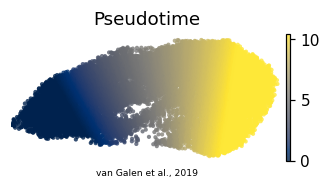

In [10]:
# sanitize non-serializable ElPiGraph uns entry (node positions kept; graph lives in uns['graph'])
sub.uns['epg'] = {'NodePositions': np.asarray(sub.uns['epg']['NodePositions'])}
sub.write(os.path.join(pth_out, 'manifold.h5ad'))
xl = sub.obsm['X_umap_lin']
xlo,xhi = np.percentile(xl[:,0],[0.3,99.7]); ylo,yhi = np.percentile(xl[:,1],[0.3,99.7])
px=(xhi-xlo)*.05; py=(yhi-ylo)*.08
plot = sub.copy(); plot.obsm['X_umap'] = plot.obsm['X_umap_lin']
fig, ax = plt.subplots(figsize=(3.5,1.5))
sc.pl.umap(plot, color='t', cmap='cividis', size=30, alpha=.8, colorbar_loc='right',
           frameon=False, show=False, ax=ax, title='Pseudotime')
ax.set_xlim(xlo-px,xhi+px); ax.set_ylim(ylo-py,yhi+py)
ax.text(.5,-.12,'van Galen et al., 2019', ha='center', transform=ax.transAxes, size=6)
fig.savefig(os.path.join(pth_fig,'manifold.pdf'), bbox_inches='tight')
print('saved manifold.h5ad + manifold.pdf')